In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, spearmanr
import python_anesthesia_simulator as pas
from scripts.new_hemo_class import NewHemoModel

In [2]:
data = pd.read_csv('data/database.csv', nrows=3000)


In [3]:
caseid = data.caseid.unique()[0]
data_case = data.query('caseid == @caseid')
age = data_case.age.iloc[0]
height = data_case.height.iloc[0]
weight = data_case.weight.iloc[0]
sex = data_case.sex.iloc[0]


model = "Eleveld"  # Eleveld model
Patient_simu = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
)

Patient_simu_dist = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
)

Patient_simu_dist.hemo_pd = NewHemoModel(
        age=Patient_simu_dist.age,
        ts=Patient_simu_dist.ts,
        random=False,
        hr_base=60,
        sv_base=6.5 / 60 * 1000,  # L to ml
        map_base=90
    )

time_max = 60*60
data_case = data_case.query('Time <= @time_max')
df_simu = Patient_simu.full_sim(
    u_propo=data_case['Propofol']*20/3600,
    u_remi=data_case['Remifentanil']*20/3600
    )
df_simu_dist = Patient_simu_dist.full_sim(
    u_propo=data_case['Propofol']*20/3600,
    u_remi=data_case['Remifentanil']*20/3600
    )

/home/aubouinb/Nextcloud2/Code/PAS_vs_vitalDB/.venv/lib/python3.12/site-packages/scipy/signal/_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)
/home/aubouinb/Nextcloud2/Code/PAS_vs_vitalDB/.venv/lib/python3.12/site-packages/scipy/signal/_lti_conversion.py:74: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  num, den = normalize(num, den)   # Strips zeros, checks arrays


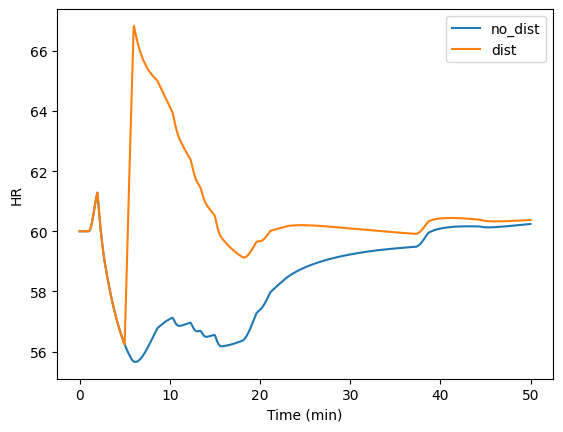

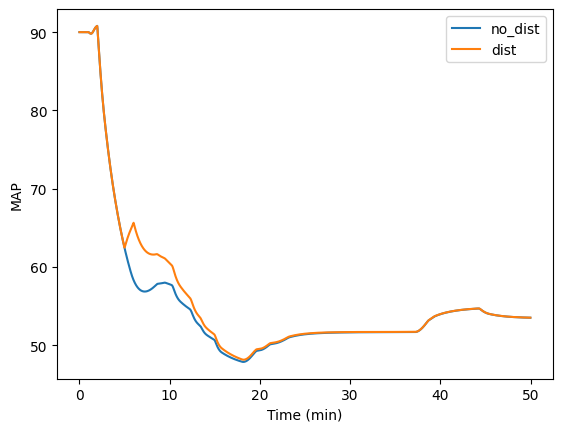

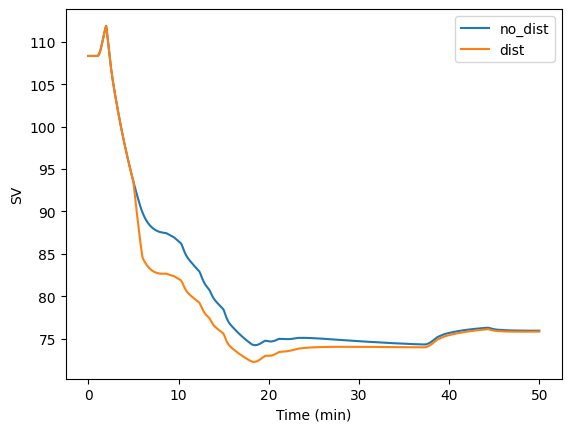

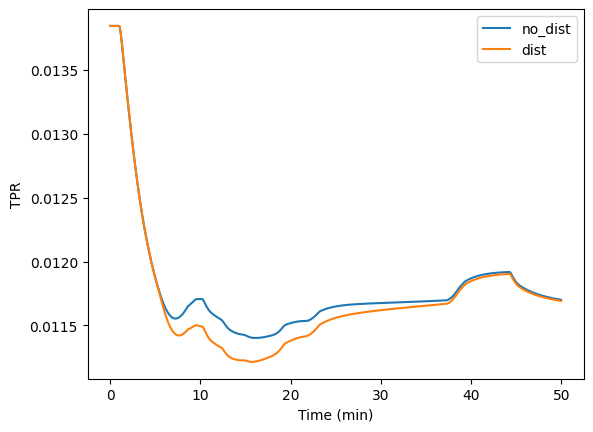

In [4]:
for signal in ['HR', 'MAP', 'SV', 'TPR']:
    plt.figure()
    plt.plot(df_simu['Time']/60, df_simu[signal], label='no_dist')
    plt.plot(df_simu_dist['Time']/60, df_simu_dist[signal], label='dist')
    plt.xlabel('Time (min)')
    plt.ylabel(f'{signal}')
    plt.legend()
    plt.show()

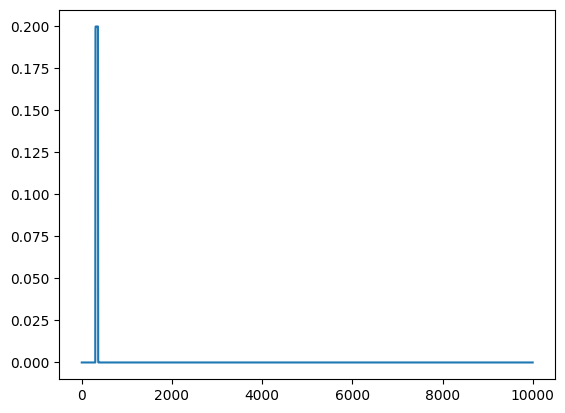

In [5]:
plt.plot(Patient_simu_dist.hemo_pd.hr_dist)